In [42]:
import json
from pathlib import Path
import polars as pl
from IPython.display import Markdown
from polars import DataFrame, LazyFrame
import polars.selectors as cs

import matplotlib.pyplot as plt
import seaborn as sns

In [43]:
sns.set_context('paper', font_scale=1.2)
sns.set_style('whitegrid')

plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.linewidth'] = .75
plt.rcParams['patch.linewidth'] = .5
plt.rcParams['grid.linewidth'] = .5
plt.rcParams['grid.linestyle'] = 'dashed'
plt.rcParams['lines.dashed_pattern'] = (10, 5)
plt.rcParams['lines.linewidth'] = .75
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.sans-serif'] = ['Libertinus Sans', 'Helvetica', 'DejaVu Sans']
plt.rcParams['font.family'] = 'sans-serif'

# Webis colours
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=[
    '#90d7de',
    '#9ed977',
    '#ffab9e',
    '#d6acfa',
    '#ffc640',
    '#68b4c2',
    '#62ba61',
    '#ff6f52',
    '#bb86f3',
    '#e8a01d',
])

In [6]:
from pan26_genai_detection.evaluator.evaluator import c_at_1, auc, f1, f05u, brier_score

def evaluate_all(y_true: pl.DataFrame, y_pred: pl.DataFrame, zero_knowledge=False):
    y_true = y_true.to_numpy()
    y_pred = y_pred.to_numpy()

    n_neg = (y_true == 0).sum()
    fpr = (y_pred[y_true == 0] >= 0.5).sum() / n_neg if n_neg else 0.0

    n_pos = (y_true == 1).sum()
    fnr = (y_pred[y_true == 1] < 0.5).sum() / n_pos if n_pos else 0.0

    results = pl.from_dict({
        'roc-auc': auc(y_true, y_pred),
        'brier': brier_score(y_true, y_pred),
        'c@1': c_at_1(y_true, y_pred),
        'f1': f1(y_true, y_pred),
        'f05u': f05u(y_true, y_pred),
    }).with_columns(
        pl.mean_horizontal(pl.all()).alias('mean'),
        pl.lit(fpr).alias('fpr'),
        pl.lit(fnr).alias('fnr'),
    )
    if zero_knowledge and results['c@1'][0] < 0.5:
        results = results.with_columns(
            (1.0 - pl.all().exclude(pl.String)).name.keep()
        )
    return results

In [7]:
TEAM_NAME_MAP = {
    'mdok': 'baseline',
    'ce-ec': 'sinai',
    'momifai': 'aimoment',
    'sst': 'dactyl',
}

def build_truth_map(truth_file: Path, id_map_file: Path | None = None):
    truth_df = pl.read_ndjson(truth_file)
    if not id_map_file:
        return truth_df.with_columns(pl.lit(None).alias('orig_id'))
    id_map_df = pl.read_ndjson(id_map_file)[['id', 'orig_id']]
    return truth_df.join(id_map_df, on='id', how='left')

def build_zero_knowledge_baseline(truth_map: pl.DataFrame, dataset: str):
    majority = 1.0 if truth_map['label'].mean() >= 0.5 else 0.0
    ids = truth_map.select('id')
    assert len(ids) == len(ids.unique())
    return pl.from_dict({
        'id': ids,
        'label': [majority] * len(ids),
        'run_id': ['0000-00-00-00-00-00'] * len(ids),
        'team': ['baseline'] * len(ids),
        'software': ['baseline-zero-knowledge'] * len(ids),
        'dataset': [dataset] * len(ids),
    })

def load_run_files(rundir: Path):
    meta_df = pl.read_ndjson(rundir / 'metadata.jsonl')
    runs_df = []
    run_ids = meta_df.select('run_id').unique().to_series()

    # Leave no stray runs behind
    assert len(run_ids) == len(list(rundir.joinpath('outputs-flat').glob('2026-*')))

    for rid in run_ids:
        runfile = rundir / 'outputs-flat' / rid
        for l in runfile.open('r'):
            j = json.loads(l)
            j['run_id'] = rid
            runs_df.append(j)

    df = pl.from_records(runs_df)
    df = (df
        .join(meta_df.select(['run_id', 'team', 'software', 'dataset']), on='run_id', how='left').
        with_columns([
            pl.col("team").replace(TEAM_NAME_MAP),
            pl.col("software").replace("mdok", "baseline-mdok"),
        ])
    )
    return df

def join_runs_and_truth(runs_df: pl.DataFrame, meta_df: pl.DataFrame):
    df = runs_df.join(meta_df, on='id', how='left')
    df = df.rename({'label': 'label_pred', 'label_right': 'label_truth'})

    # Sanity check
    assert df['label_truth'].is_not_null().all()
    assert df['label_pred'].is_not_null().all()

    # Reorder columns and sort
    col_order = ['team', 'software', 'run_id', 'id', 'orig_id', 'model', 'label_pred', 'label_truth', 'dataset']
    if 'source' in df.columns:
        col_order.insert(col_order.index('label_pred'), 'source')
    elif 'approach' in df.columns:
        df = df.rename({'approach': 'source'})
        col_order.insert(col_order.index('label_pred'), 'source')
    df = df.select(col_order)
    df = df.sort(by=['team', 'software', 'run_id', 'model', 'label_truth'])
    return df

def load_run_truth_and_meta(base_path: Path, truth_file: Path, id_map_file: Path | None = None):
    truth_map = build_truth_map(truth_file, id_map_file)
    runs_pan26 = load_run_files(base_path)
    zero_knowledge = build_zero_knowledge_baseline(truth_map, runs_pan26['dataset'].unique()[0])
    runs_pan26 = pl.concat([runs_pan26, zero_knowledge])
    return join_runs_and_truth(runs_pan26, truth_map)

def print_run_stats(df):
    df = df.filter(pl.col('team') != 'baseline')
    print(f'Predictions: {len(df):,}')
    print(f'Runs: {len(df["run_id"].unique())}')
    print(f'Softwares: {len(df[["team", "software"]].unique())}')
    print(f'Teams: {len(df["team"].unique())}')

In [8]:
BASE_PATH = Path('../data')
BASE_EVAL_PATH = BASE_PATH / 'task-eval'
BASE_RUN_PATH = BASE_EVAL_PATH / 'tira-runs'

In [109]:
pan25_df = load_run_truth_and_meta(BASE_RUN_PATH / 'pan25',
                                   BASE_PATH / 'splits' / 'pan25-voight-kampff-test-truth.jsonl')
print_run_stats(pan25_df)

Predictions: 777,750
Runs: 150
Softwares: 136
Teams: 34


In [136]:
def add_gen_cond_col(df):
    """
    Extract the correct generation conditions from orig_id.
    The 'source' field doesn't contain all needed information.
    """
    cond_label_map = {
        'brown-cont': 'Brown Continuation',
        'llama-3.3-70b-instruct-8bit-rtop1': 'Llama Reverse Top-1',
        'llama-3.3-70b-instruct-8bit-watermark-gamma05-bias5-temp1': 'KGW 0.05/5',
        'nytimes-writing-prompts': 'NYT Prompts Unobfuscated',
        'nytimes-writing-prompts-reverse-swahili-translated': 'NYT Prompts Reverse Swahili',
        'nytimes-writing-prompts-tibet-translated-en': 'NYT Prompts Translated 1',
        'nytimes-writing-prompts-tibet-translated-en-zh-fa-en': 'NYT Prompts Translated 3',
        'nytimes-writing-prompts-tibet-translated-mr-kk-ja-lo-iw-am-en': 'NYT Prompts Translated 7',
        'nytimes-writing-prompts-translated-en-obfs': 'NYT Prompts Heuristic Obf.',
    }


    return df.with_columns(
        pl.when(pl.col('orig_id').str.starts_with('llama'))
        .then(pl.col('orig_id').str.split('/').list.get(0, null_on_oob=True))
        .otherwise(pl.col('orig_id').str.split('/').list.get(1, null_on_oob=True))
        .alias('gen_cond')
    ).with_columns(
        pl.when(pl.col('gen_cond').is_in(['brown', 'brown-cont']))
        .then(pl.lit('brown-cont'))
        .otherwise(pl.col('gen_cond'))
        .replace(cond_label_map)
        .alias('gen_cond')
    )

In [137]:
pan26_df = load_run_truth_and_meta(BASE_RUN_PATH / 'pan26',
                                   BASE_PATH / 'splits' / 'pan26-voight-kampff-test-truth.jsonl',
                                   BASE_PATH / 'sampled' / 'pan26-voight-kampff-orig-ids.jsonl')
pan26_df = add_gen_cond_col(pan26_df)
print_run_stats(pan26_df)

Predictions: 318,686
Runs: 158
Softwares: 137
Teams: 34


In [138]:
eloquent26_df = load_run_truth_and_meta(BASE_RUN_PATH / 'eloquent26',
                                   BASE_PATH / 'splits' / 'eloquent26-truth.jsonl',
                                   BASE_PATH / 'splits' / 'eloquent26-truth.jsonl')
eloquent26_df = add_gen_cond_col(eloquent26_df)
print_run_stats(eloquent26_df)

Predictions: 58,240
Runs: 140
Softwares: 136
Teams: 34


In [112]:
all_df = pl.concat([pan26_df, eloquent26_df])
print_run_stats(all_df)

Predictions: 376,926
Runs: 298
Softwares: 137
Teams: 34


In [12]:
def get_results_grouped(df: pl.DataFrame, group_cols=None):
    if not group_cols:
        group_cols = ['team', 'software', 'run_id', 'dataset']

    def evaluate_group(key, group_df):
        metrics = evaluate_all(
            group_df.select('label_truth'),
            group_df.select('label_pred'),
            zero_knowledge=(key[:2] == ('baseline', 'baseline-zero-knowledge'))
        )
        keys = pl.DataFrame([dict(zip(group_cols, key))])
        return pl.concat([keys, metrics], how='horizontal')

    df = pl.concat(
        evaluate_group(key, group_df)
        for key, group_df in df.partition_by(
            group_cols,
            as_dict=True,
            maintain_order=True,
        ).items()
    ).sort(by='mean', descending=True)
    return df

def get_best_by_team(result_per_run_df: pl.DataFrame, with_baselines=True):
    result_per_run_df = result_per_run_df.sort(['mean'], descending=True)
    best_by_team = result_per_run_df.filter(pl.col('team') != 'baseline').unique(subset='team', keep='first', maintain_order=True)
    if not with_baselines:
        return best_by_team

    baseline_runs = result_per_run_df.filter(pl.col('team') == 'baseline')
    return pl.concat([best_by_team, baseline_runs]).sort('mean', descending=True)

In [118]:
results_per_run25 = get_results_grouped(pan25_df)
results_per_run26 = get_results_grouped(pan26_df)
results_per_run26_all = get_results_grouped(all_df)
results_per_run_eloquent26 = get_results_grouped(eloquent26_df)

In [14]:
display(Markdown('# PAN\'25 Dataset:'))
with pl.Config(float_precision=3, tbl_rows=-1):
    display(get_best_by_team(results_per_run25).drop(['run_id', 'dataset']))

# PAN'25 Dataset:

team,software,roc-auc,brier,c@1,f1,f05u,mean,fpr,fnr
str,str,f64,f64,f64,f64,f64,f64,f64,f64
"""baseline""","""baseline-mdok""",0.997,0.988,0.986,0.990,0.994,0.991,0.006,0.017
"""plagiarism-detector-com-reg2""","""alternating-contingency""",0.999,0.986,0.983,0.981,0.992,0.988,0.001,0.024
"""turingteam""","""marinated-edge""",0.995,0.979,0.980,0.983,0.991,0.986,0.010,0.025
"""dsgt-pan-26""","""relaxed-copy""",0.998,0.977,0.972,0.979,0.990,0.983,0.005,0.038
"""suspiciously-coherent""","""lead-log""",0.998,0.980,0.970,0.979,0.967,0.979,0.098,0.001
"""styloch2026""","""instant-tartar""",0.988,0.967,0.965,0.975,0.989,0.977,0.003,0.048
"""dactyl""","""DeBERTa-V3-large-individual""",0.987,0.969,0.965,0.975,0.987,0.977,0.010,0.045
"""ak-ys""","""Qwen3-0.6B-fine-tuned (dockerf…",0.991,0.957,0.949,0.962,0.982,0.968,0.009,0.069
"""zhengqiaozeng""","""three""",0.978,0.931,0.929,0.946,0.976,0.952,0.006,0.099


In [15]:
display(Markdown('# PAN\'26 Dataset:'))

leaderboard26 = get_best_by_team(results_per_run26)
leaderboard26_pandas = leaderboard26.drop(['run_id', 'dataset']).to_pandas()
leaderboard26_pandas.to_html(BASE_EVAL_PATH / 'pan26-leaderboard.html', index=True, float_format=lambda x: f"{x:.3f}")
leaderboard26_pandas[['team', 'roc-auc', 'brier', 'c@1', 'f1', 'f05u',  'mean', 'fpr', 'fnr']].to_latex(BASE_EVAL_PATH / 'pan26-leaderboard.tex', index=True, float_format=lambda x: f"{x:.3f}")

with pl.Config(float_precision=3, tbl_rows=-1):
    display(leaderboard26.drop(['run_id', 'dataset']))

# PAN'26 Dataset:

team,software,roc-auc,brier,c@1,f1,f05u,mean,fpr,fnr
str,str,f64,f64,f64,f64,f64,f64,f64,f64
"""suspiciously-coherent""","""lead-log""",0.989,0.965,0.965,0.976,0.980,0.975,0.053,0.029
"""dactyl""","""ModernBERT-large-BNN""",0.993,0.970,0.962,0.975,0.969,0.974,0.108,0.014
"""plagiarism-detector-com-reg2""","""organic-tube""",0.997,0.958,0.949,0.955,0.982,0.968,0.000,0.067
"""baseline""","""baseline-mdok""",0.995,0.951,0.946,0.963,0.984,0.968,0.002,0.072
"""dsgt-pan-26""","""relaxed-copy""",0.981,0.885,0.873,0.907,0.961,0.921,0.000,0.170
"""ydong""","""ydong""",0.930,0.915,0.886,0.928,0.896,0.911,0.420,0.014
"""turingteam""","""marinated-edge""",0.957,0.882,0.846,0.851,0.925,0.892,0.053,0.179
"""writerslogic-inc""","""large-rank""",0.891,0.891,0.853,0.902,0.899,0.887,0.312,0.092
"""a-a-detection""","""navy-iceberg""",0.852,0.848,0.826,0.885,0.880,0.858,0.375,0.106


In [16]:
display(Markdown('# ELOQUENT\'26 Dataset:'))

leaderboard_eloquent26 = get_best_by_team(results_per_run_eloquent26)
leaderboard_eloquent26_pandas = leaderboard_eloquent26.drop(['run_id', 'dataset']).to_pandas()
leaderboard_eloquent26_pandas.to_html(BASE_EVAL_PATH / 'eloquent26-leaderboard.html', index=True, float_format=lambda x: f"{x:.3f}")

with pl.Config(float_precision=3, tbl_rows=-1):
    display(leaderboard_eloquent26.drop(['run_id', 'dataset']))

# ELOQUENT'26 Dataset:

team,software,roc-auc,brier,c@1,f1,f05u,mean,fpr,fnr
str,str,f64,f64,f64,f64,f64,f64,f64,f64
"""ikr3""","""lexical + semantic LR""",0.929,0.958,0.952,0.975,0.961,0.955,1.000,0.000
"""plagiarism-detector-com-reg2""","""organic-tube""",0.988,0.932,0.909,0.940,0.975,0.949,0.000,0.093
"""turingteam""","""marinated-edge""",0.987,0.922,0.912,0.930,0.970,0.944,0.100,0.086
"""dactyl""","""ModernBERT-large-individual""",0.927,0.910,0.873,0.929,0.961,0.920,0.300,0.119
"""suspiciously-coherent""","""lead-log""",0.961,0.858,0.853,0.917,0.963,0.911,0.050,0.152
"""ydong""","""ydong""",0.957,0.882,0.830,0.897,0.954,0.904,0.100,0.174
"""baseline""","""baseline-mdok""",0.928,0.865,0.844,0.911,0.958,0.901,0.150,0.157
"""a-a-detection""","""navy-iceberg""",0.915,0.847,0.849,0.915,0.957,0.897,0.200,0.149
"""egrantha-ai""","""faded-noir""",0.500,0.952,0.952,0.975,0.961,0.868,1.000,0.000


In [69]:
display(Markdown('# PAN\'26 + ELOQUENT Dataset:'))
leaderboard26_all = get_best_by_team(results_per_run26_all)

with pl.Config(float_precision=3, tbl_rows=-1):
    display(leaderboard26_all.drop(['run_id', 'dataset']))

# PAN'26 + ELOQUENT Dataset:

team,software,roc-auc,brier,c@1,f1,f05u,mean,fpr,fnr
str,str,f64,f64,f64,f64,f64,f64,f64,f64
"""suspiciously-coherent""","""lead-log""",0.989,0.965,0.965,0.976,0.980,0.975,0.053,0.029
"""dactyl""","""ModernBERT-large-BNN""",0.993,0.970,0.962,0.975,0.969,0.974,0.108,0.014
"""plagiarism-detector-com-reg2""","""organic-tube""",0.997,0.958,0.949,0.955,0.982,0.968,0.000,0.067
"""baseline""","""baseline-mdok""",0.995,0.951,0.946,0.963,0.984,0.968,0.002,0.072
"""ikr3""","""lexical + semantic LR""",0.929,0.958,0.952,0.975,0.961,0.955,1.000,0.000
"""turingteam""","""marinated-edge""",0.987,0.922,0.912,0.930,0.970,0.944,0.100,0.086
"""dsgt-pan-26""","""relaxed-copy""",0.981,0.885,0.873,0.907,0.961,0.921,0.000,0.170
"""ydong""","""ydong""",0.930,0.915,0.886,0.928,0.896,0.911,0.420,0.014
"""baseline""","""baseline-mdok""",0.928,0.865,0.844,0.911,0.958,0.901,0.150,0.157


In [17]:
display(Markdown('# ELOQUENT\'26 Leaderboard (All PAN Systems):'))

eloquent_leaderboard26_all = eloquent26_df.join(leaderboard26.filter(pl.col("team") != "baseline"), on=['team', 'software'], how='semi')
eloquent_leaderboard26_all = get_results_grouped(eloquent_leaderboard26_all, group_cols=['source', 'dataset'])
eloquent_leaderboard26_all = eloquent_leaderboard26_all.sort('c@1').drop('roc-auc')

with pl.Config(float_precision=3, tbl_rows=-1):
    display(eloquent_leaderboard26_all)
eloquent_leaderboard26_all.write_csv(BASE_EVAL_PATH / 'eloquent26-leaderboard-all-pan.csv')

# ELOQUENT'26 Leaderboard (All PAN Systems):

source,dataset,brier,c@1,f1,f05u,mean,fpr,fnr
str,str,f64,f64,f64,f64,f64,f64,f64
"""uts-claude-v11 - Dima G""","""eloquent-20260617-test""",0.342,0.230,0.364,0.589,0.382,0.000,0.744
"""uts-claude-v4 - Dima G""","""eloquent-20260617-test""",0.355,0.282,0.430,0.654,0.430,0.000,0.697
"""uts-claude-v7 - Dima G""","""eloquent-20260617-test""",0.446,0.340,0.496,0.711,0.498,0.000,0.639
"""claude-opus-4-7_roundtrip_impe…","""eloquent-20260617-test""",0.413,0.347,0.504,0.718,0.495,0.000,0.633
"""uts-qwen-v7 - Dima G""","""eloquent-20260617-test""",0.555,0.470,0.625,0.806,0.614,0.000,0.511
"""Dargk_LoRA_beta0 - Juan Manuel…","""eloquent-20260617-test""",0.569,0.484,0.632,0.811,0.624,0.000,0.492
"""rejection_sample_opus - Dima G""","""eloquent-20260617-test""",0.590,0.485,0.634,0.812,0.630,0.000,0.491
"""claude-opus-4-7_source_anchore…","""eloquent-20260617-test""",0.600,0.501,0.651,0.824,0.644,0.000,0.479
"""Dargk - Juan Manuel Rodriguez""","""eloquent-20260617-test""",0.626,0.563,0.700,0.854,0.686,0.000,0.416


In [18]:
display(Markdown('# ELOQUENT\'26 Leaderboard (Top-10 PAN systems):'))

eloquent_leaderboard26_top10 = eloquent26_df.join(leaderboard26.filter(pl.col("team") != "baseline").head(10), on=['team', 'software'], how='semi')
eloquent_leaderboard26_top10 = get_results_grouped(eloquent_leaderboard26_top10, group_cols=['source', 'dataset'])
eloquent_leaderboard26_top10 = eloquent_leaderboard26_top10.sort('c@1').drop('roc-auc')

with pl.Config(float_precision=3, tbl_rows=-1):
    display(eloquent_leaderboard26_top10)
eloquent_leaderboard26_top10.write_csv(BASE_EVAL_PATH / 'eloquent26-leaderboard-top10-pan.csv')

# ELOQUENT'26 Leaderboard (Top-10 PAN systems):

source,dataset,brier,c@1,f1,f05u,mean,fpr,fnr
str,str,f64,f64,f64,f64,f64,f64,f64
"""uts-claude-v11 - Dima G""","""eloquent-20260617-test""",0.482,0.372,0.538,0.744,0.534,0.000,0.623
"""uts-claude-v7 - Dima G""","""eloquent-20260617-test""",0.652,0.598,0.746,0.880,0.719,0.000,0.400
"""uts-claude-v4 - Dima G""","""eloquent-20260617-test""",0.652,0.623,0.768,0.892,0.733,0.000,0.377
"""rejection_sample_opus - Dima G""","""eloquent-20260617-test""",0.699,0.659,0.788,0.903,0.762,0.000,0.336
"""claude-opus-4-7_source_anchore…","""eloquent-20260617-test""",0.728,0.676,0.804,0.911,0.780,0.000,0.323
"""Dargk_LoRA_beta0 - Juan Manuel…","""eloquent-20260617-test""",0.750,0.694,0.812,0.915,0.793,0.000,0.302
"""claude-opus-4-7_roundtrip_impe…","""eloquent-20260617-test""",0.713,0.712,0.830,0.924,0.795,0.000,0.286
"""uts-qwen-v7 - Dima G""","""eloquent-20260617-test""",0.764,0.714,0.833,0.926,0.809,0.000,0.286
"""Dargk - Juan Manuel Rodriguez""","""eloquent-20260617-test""",0.837,0.812,0.892,0.954,0.874,0.000,0.186


In [139]:
best_run_ids = (leaderboard26
                .filter(pl.col('team') != 'baseline')
                .select('run_id'))
top10_run_ids = (leaderboard26
                 .filter(pl.col('team') != 'baseline')
                 .head(10)
                 .select('run_id'))

pan26_df_filtered_best = pan26_df.join(
    best_run_ids,
    on='run_id',
    how='semi'
)
pan26_df_filtered_best_top10 = pan26_df.join(
    top10_run_ids,
    on='run_id',
    how='semi'
)
eloquent_df_filtered_best = eloquent26_df.join(
    best_run_ids,
    on='run_id',
    how='semi'
)
eloquent_df_filtered_best_top10 = eloquent26_df.join(
    top10_run_ids,
    on='run_id',
    how='semi'
)
all_df_filtered_best = all_df.join(
    best_run_ids,
    on='run_id',
    how='semi'
)
all_df_filtered_best_top10 = all_df.join(
    top10_run_ids,
    on='run_id',
    how='semi'
)

In [44]:
# get_results_grouped(pan26_df_filtered_best.filter(
#     pl.col('source').str.starts_with('brown')
# )).drop(['run_id', 'dataset'])

In [45]:
# get_results_grouped(pan26_df_filtered_best.filter(
#     (pl.col('source') == 'nytimes-writing-prompts-tibet-translated-en') |
#     ((pl.col('source') == 'nytimes-writing-prompts') & (pl.col('label_truth') == 0))
# )).drop(['run_id', 'dataset'])

In [46]:
# get_results_grouped(pan26_df_filtered_best.filter(
#     (pl.col('source') == 'nytimes-writing-prompts-tibet-translated-en-zh-fa-en') |
#     ((pl.col('source') == 'nytimes-writing-prompts') & (pl.col('label_truth') == 0))
# )).drop(['run_id', 'dataset'])

In [47]:
# get_results_grouped(pan26_df_filtered_best.filter(
#     (pl.col('source') == 'nytimes-writing-prompts-tibet-translated-mr-kk-ja-lo-iw-am-en') |
#     ((pl.col('source') == 'nytimes-writing-prompts') & (pl.col('label_truth') == 0))
# )).drop(['run_id', 'dataset'])

In [48]:
# get_results_grouped(pan26_df_filtered_best.filter(
#     (pl.col('source') == 'nytimes-writing-prompts-translated-en-obfs') |
#     ((pl.col('source') == 'nytimes-writing-prompts') & (pl.col('label_truth') == 0))
# )).drop(['run_id', 'dataset'])

In [49]:
# get_results_grouped(pan26_df_filtered_best.filter(
#     (pl.col('source') == 'nytimes-writing-prompts-reverse-swahili-translated') |
#     ((pl.col('source') == 'nytimes-writing-prompts') & (pl.col('label_truth') == 0))
# )).drop(['run_id', 'dataset'])

In [50]:
# get_results_grouped(pan26_df_filtered_best.filter(
#     ((pl.col('model') == 'gpt-5.5') | (pl.col('model') == 'human')) &
#     pl.col('source').str.starts_with('brown')
# )).drop(['run_id', 'dataset'])

In [51]:
# get_results_grouped(pan26_df_filtered_best.filter(
#     ((pl.col('model') == 'gpt-5.5') | (pl.col('model') == 'human')) &
#     pl.col('source').str.starts_with('nytimes')
# )).drop(['run_id', 'dataset'])

In [52]:
# get_results_grouped(pan26_df_filtered_best.filter(
#     ((pl.col('model') == 'gpt-5.4') | (pl.col('model') == 'human')) &
#     pl.col('source').str.starts_with('nytimes')
# )).drop(['run_id', 'dataset'])

In [53]:
# get_results_grouped(pan26_df_filtered_best.filter(
#     ((pl.col('model') == 'gpt-4o') | (pl.col('model') == 'human')) &
#     pl.col('source').str.starts_with('nytimes')
# )).drop(['run_id', 'dataset'])

In [54]:
# get_results_grouped(pan26_df_filtered_best.filter(
#     ((pl.col('model') == 'llama-3.3-70b-instruct-8bit-rtop1') | (pl.col('model') == 'human')) &
#     pl.col('source').str.starts_with('nytimes')
# )).drop(['run_id', 'dataset'])

In [55]:
# get_results_grouped(pan26_df_filtered_best.filter(
#     ((pl.col('model') == 'llama-3.3-70b-instruct-8bit-watermark-gamma05-bias5-temp1') | (pl.col('model') == 'human')) &
#     pl.col('source').str.starts_with('nytimes')
# )).drop(['run_id', 'dataset'])

In [56]:
# get_results_grouped(pan26_df_filtered_best.filter(
#     ((pl.col('model') == 'nytimes-writing-prompts-translated-en-heuristic_obfs') | (pl.col('model') == 'human')) &
#     pl.col('source').str.starts_with('nytimes')
# )).drop(['run_id', 'dataset'])

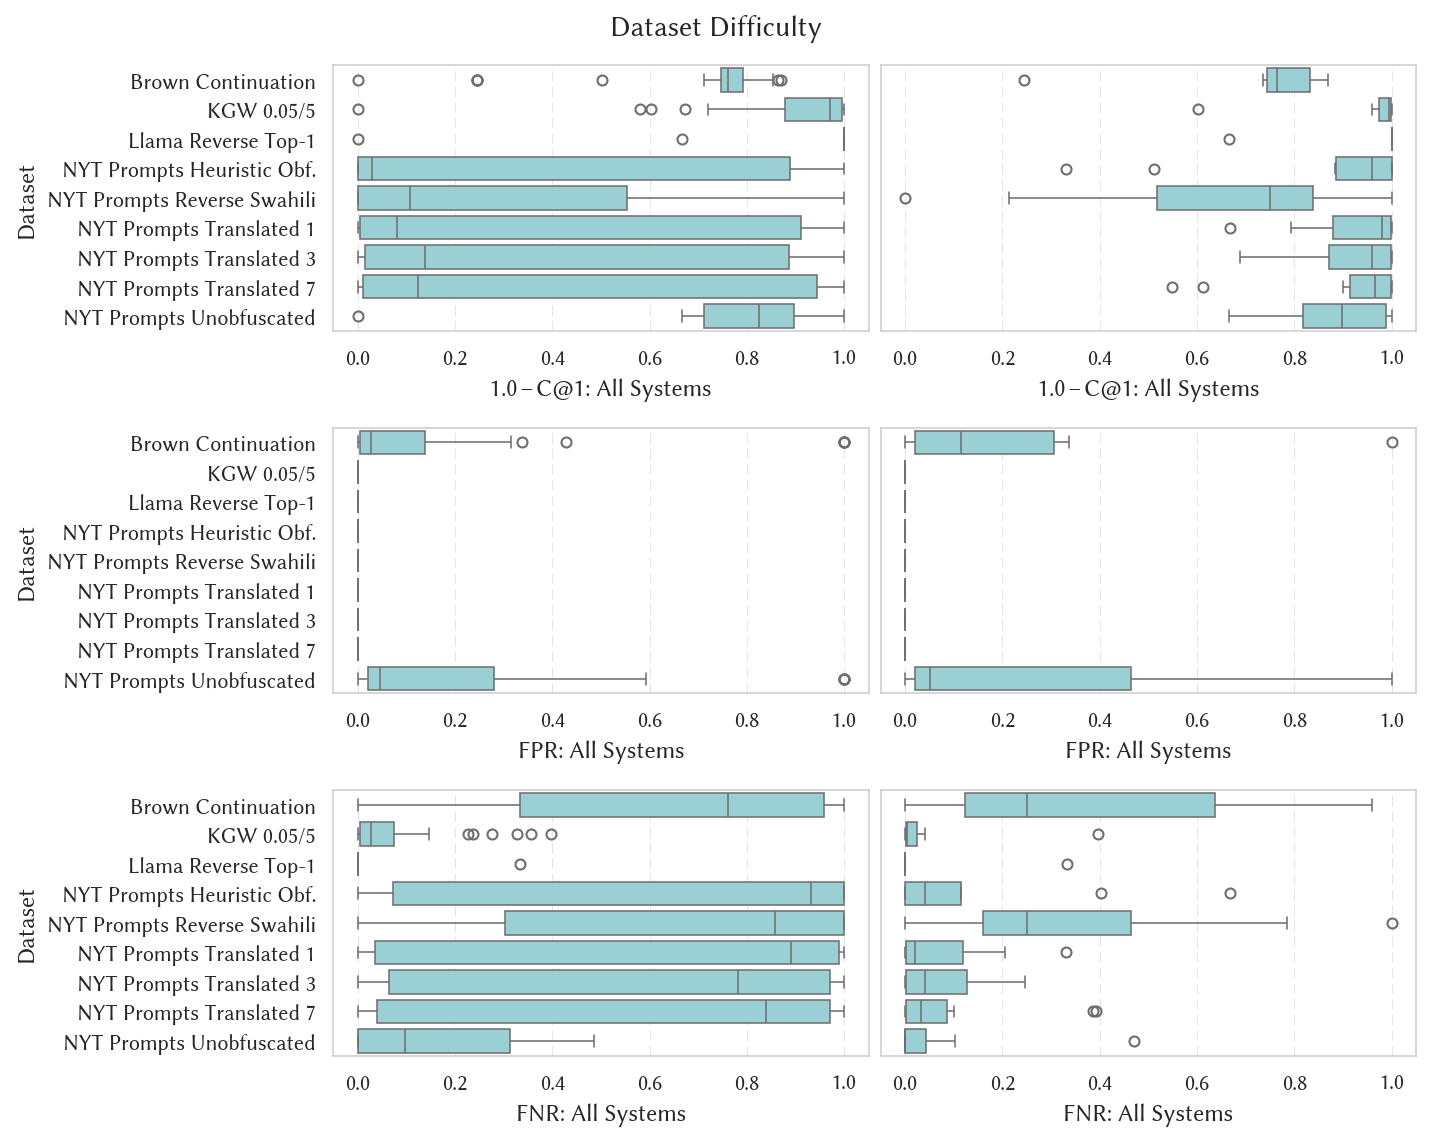

In [146]:
def _plt_dataset_difficulty(ax, df, field, xlabel, order, group_field='gen_cond', ylabel='Dataset'):
    sns.boxplot(df, ax=ax, x=field, y=group_field, order=order, linewidth=.75)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xlim((-.05, 1.05))

fig, axs = plt.subplots(3, 2, figsize=(9.5, 7.5), sharey='row')
# fig, axs = plt.subplots(1, 2, figsize=(9, 2.8), sharey='row')

results_per_source = get_results_grouped(pan26_df_filtered_best, group_cols=['team', 'software', 'dataset', 'gen_cond'])
results_per_source_top10 = get_results_grouped(pan26_df_filtered_best_top10, group_cols=['team', 'software', 'dataset', 'gen_cond'])

order = results_per_source['gen_cond'].unique().sort()

_plt_dataset_difficulty(axs.flat[0],
                        results_per_source,
                        'c@1',
                        '1.0 – C@1: All Systems',
                        order)

_plt_dataset_difficulty(axs.flat[1],
                        results_per_source_top10,
                        'c@1',
                        '1.0 – C@1: All Systems',
                        order)

_plt_dataset_difficulty(axs.flat[2],
                        results_per_source,
                        'fpr',
                        'FPR: All Systems',
                        order)

_plt_dataset_difficulty(axs.flat[3],
                        results_per_source_top10,
                        'fpr',
                        'FPR: All Systems',
                        order)

_plt_dataset_difficulty(axs.flat[4],
                        results_per_source,
                        'fnr',
                        'FNR: All Systems',
                        order)

_plt_dataset_difficulty(axs.flat[5],
                        results_per_source_top10,
                        'fnr',
                        'FNR: All Systems',
                        order)

plt.suptitle('Dataset Difficulty', y=.999)
plt.tight_layout(pad=.5, h_pad=1.1)
# plt.savefig(OUT_DIR / 'pan_dataset_difficulty.pdf')
plt.show()